In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box
import numpy as np

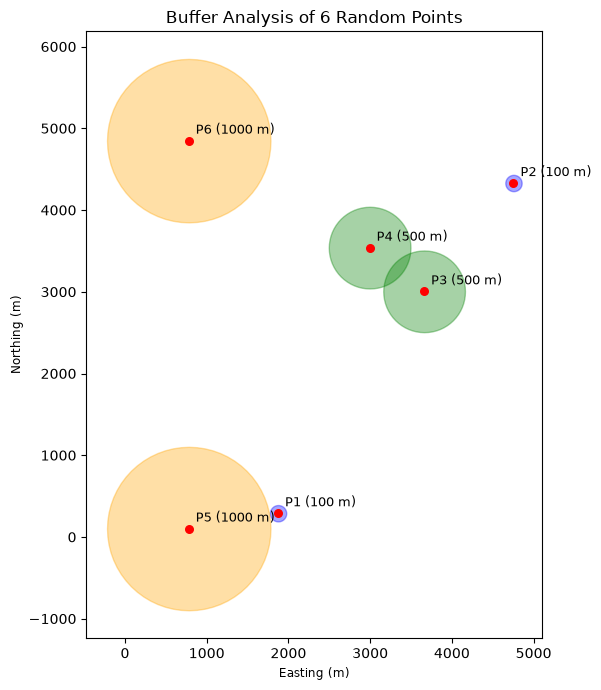

In [2]:
'''1. Generate random points using geopandas and create a buffer of 100m, 500m and 
1km around the points. Plot the results using Matplotlib. '''

np.random.seed(42)
x = np.random.uniform(0, 5000, 6)
y = np.random.uniform(0, 5000, 6)

points = gpd.GeoDataFrame(
    {"ID": range(1, 7)},
    geometry=[Point(a, b) for a, b in zip(x, y)],
    crs="EPSG:32643"
)

distances = [100, 100, 500, 500, 1000, 1000]
colors = ["blue", "blue", "green", "green", "orange", "orange"]

fig, ax = plt.subplots(figsize=(9, 7))

for i, distance in enumerate(distances):
    buffer = points.geometry.iloc[i].buffer(distance)

    gpd.GeoSeries(
        [buffer], crs=points.crs
    ).plot(
        ax=ax,
        color=colors[i],
        edgecolor=colors[i],
        alpha=0.35
    )

points.plot(ax=ax, color="red", markersize=30)

for i, point in enumerate(points.geometry):
    ax.annotate(
        f"P{i+1} ({distances[i]} m)",
        (point.x, point.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Buffer Analysis of 6 Random Points")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()


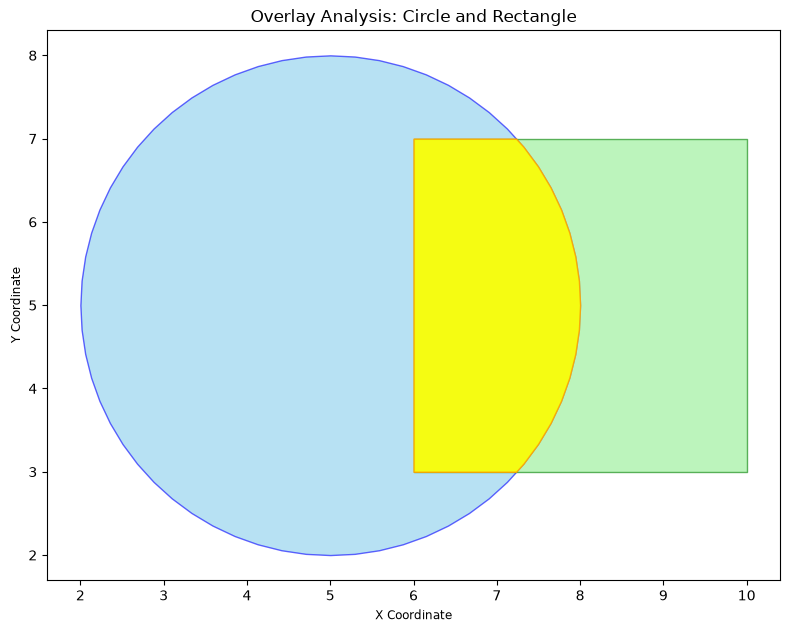

In [3]:
""" 2. Generate a circular polygon and a rectangular polygon with overlapping shapes 
using Geopandas. Overlay these polygons using geopandas overlay function and 
plot the results."""

circle = Point(5, 5).buffer(3)
rectangle = box(6, 3, 10, 7)

gdf_circle = gpd.GeoDataFrame(
    {"name": ["Circle"]},
    geometry=[circle],
    crs="EPSG:32643"
)

gdf_rectangle = gpd.GeoDataFrame(
    {"name": ["Rectangle"]},
    geometry=[rectangle],
    crs="EPSG:32643"
)

overlap = gpd.overlay(
    gdf_circle,
    gdf_rectangle,
    how="intersection"
)

fig, ax = plt.subplots(figsize=(8, 7))

gdf_circle.plot(
    ax=ax, color="skyblue",
    edgecolor="blue", alpha=0.6,
    label="Circle"
)

gdf_rectangle.plot(
    ax=ax, color="lightgreen",
    edgecolor="green", alpha=0.6,
    label="Rectangle"
)

overlap.plot(
    ax=ax, color="yellow",
    edgecolor="orange", alpha=0.9,
    label="Overlapping Area"
)

ax.set_title("Overlay Analysis: Circle and Rectangle")
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [4]:

"""3. Explore the given data (print results like count of forests from LULC data, Primary 
road names from road data etc. It can be of your choice) and print the area of 
Nedumangad """

import os
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box
import numpy as np
from pathlib import Path

data_dir = None
for base in [Path.cwd(), *Path.cwd().parents]:
    candidates = [
        base / "MTech26" / "lab 6" / "nedumangad_extracted" / "nedumangad",
        base / "Lab6" / "MTech26" / "lab 6" / "nedumangad_extracted" / "nedumangad",
    ]
    data_dir = next((path for path in candidates if path.exists()), None)
    if data_dir is not None:
        break

if data_dir is None:
    raise FileNotFoundError("Could not locate the Nedumangad extracted data directory.")

lulc = gpd.read_file(data_dir / "landuse" / "nedumangad_landuse.shp")
roads = gpd.read_file(data_dir / "roads" / "nedumangad_road.shp")
boundary = gpd.read_file(data_dir / "nedumangad_boundary.shp")

print("Landuse columns:", lulc.columns.tolist())
print("Road columns:", roads.columns.tolist())
print("Boundary columns:", boundary.columns.tolist())

forest = lulc[lulc["fclass"].str.contains("forest", case=False, na=False)]

print("Total number of forest features:", len(forest))


print("\nPrimary road names:")
primary_roads = roads[roads["fclass"] == "primary"]
print(primary_roads["name"].dropna().unique()[:10])


boundary_projected = boundary.to_crs(epsg=32643)
area_km2 = boundary_projected.geometry.area.sum() / 1_000_000

print("\nArea of Nedumangad:", round(area_km2, 3), "sq. km")


Landuse columns: ['osm_id', 'code', 'fclass', 'name', 'geometry']
Road columns: ['fid', 'osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'geometry']
Boundary columns: ['GID_3', 'GID_0', 'COUNTRY', 'GID_1', 'NAME_1', 'NL_NAME_1', 'GID_2', 'NAME_2', 'NL_NAME_2', 'NAME_3', 'VARNAME_3', 'NL_NAME_3', 'TYPE_3', 'ENGTYPE_3', 'CC_3', 'HASC_3', 'geometry']
Total number of forest features: 53

Primary road names:
<StringArray>
[         'Nedumangad - Shorlacode Road',
            'Attingal - Nedumangad Road',
     'Thiruvananthapuram - Ponmudi Road',
 'Varkala - Parippally - Madathara Road',
              'Nedumangad - Mancha Road',
                  'Mannanthala Junction',
     'Thiruvanathapuram - Thenmala Road',
                               'MC Road',
                         'MC Road(SH-1)',
          'Kazhakoottam-Kilimanoor Road']
Length: 10, dtype: str

Area of Nedumangad: 918.438 sq. km


In [5]:
"""4. Find the buildings that are within 200m distance of rivers and streams and print the 
name of the buildings (10 names). Plot the results. """

buildings = gpd.read_file(data_dir / "buildings" / "nedumangad_buildings.shp")
waterways = gpd.read_file(data_dir / "waterways" / "nedumangad_waterways.shp")

buildings = buildings.to_crs(epsg=32643)
waterways = waterways.to_crs(epsg=32643)

rivers_streams = waterways[
    waterways["fclass"].astype(str).str.lower().str.strip()
    .isin(["river", "stream"])
].copy()

print("Rivers and streams found:", len(rivers_streams))

water_buffer_union = rivers_streams.geometry.buffer(200).union_all()

buildings_near_water = buildings[
    buildings.geometry.intersects(water_buffer_union)
].copy()

print("Total buildings within 200 m:", len(buildings_near_water))

print("\nNames of 10 buildings:")
print(
    buildings_near_water["name"]
    .dropna()
    .drop_duplicates()
    .head(10)
    .to_string(index=False)
)

Rivers and streams found: 3914
Total buildings within 200 m: 31778

Names of 10 buildings:
Nedumangad Traffic Police Station
          Post Office, Nedumangad
                        Rajadhani
                   Venad Hospital
 Ponnumangalam SriTampuran Temple
       Pazhavadi Ganapathy Temple
                SIST Girls Hostel
  EI lab EC lab n Mechanical Labs
              SIST 1st year Block
            M Tech Block And Labs


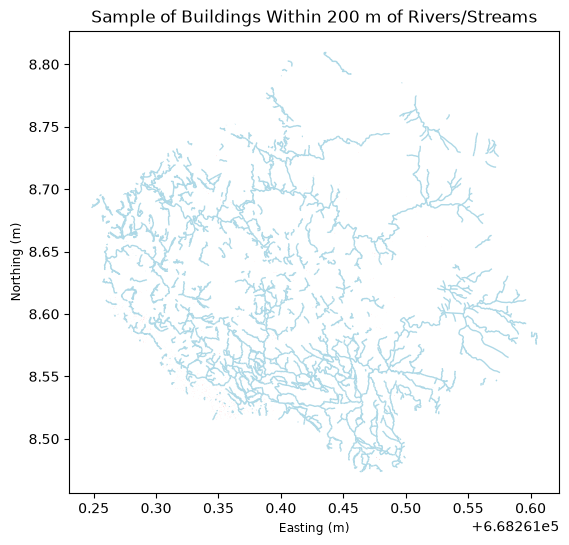

In [6]:
ax = rivers_streams.plot(
    figsize=(8, 6),
    color="lightblue",
    linewidth=1
)

buildings_to_plot = buildings_near_water.sample(
    n=min(1000, len(buildings_near_water)),
    random_state=42
)

buildings_to_plot.plot(
    ax=ax,
    color="red",
    markersize=4
)

plt.title("Sample of Buildings Within 200 m of Rivers/Streams")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show(block=False)

In [7]:
""" 5. Find the hospitals that are within 750m distance of primary and trunk roads and 
print the name of the hospitals (10 names). Plot the results. """
hospitals = buildings[
    buildings["name"].astype(str).str.contains(
        "hospital", case=False, na=False
    )
].copy()

print("Number of hospitals identified:", len(hospitals))

if buildings.crs is None or roads.crs is None:
    raise ValueError("Check the CRS of the shapefiles before proceeding.")

hospitals = hospitals.to_crs(epsg=32643)

primary_trunk_roads = roads[
    roads["fclass"].astype(str).str.lower().isin(
        ["primary", "trunk"]
    )
].to_crs(epsg=32643)

print("\nNumber of primary and trunk road features:",
      len(primary_trunk_roads))

buffer_union = primary_trunk_roads.geometry.buffer(750).union_all()

near_hospitals = hospitals[
    hospitals.geometry.intersects(buffer_union)
].copy()

print("\nHospitals within 750 m of primary and trunk roads:")

hospital_names = near_hospitals["name"].dropna().drop_duplicates()

print(hospital_names.head(10).to_string(index=False))
print("\nTotal hospitals found:", len(near_hospitals))


Number of hospitals identified: 54

Number of primary and trunk road features: 128

Hospitals within 750 m of primary and trunk roads:
                      Venad Hospital
                  Ayurvedic Hospital
             DPMS Hospital Karakulam
    RIMS Hospital  (not functioning)
        Karunya Hospital, Pothencode
        SUT Medical College Hospital
                SUT Hospital Canteen
                     Mammal hospital
Government Homoeo Hospital Karakulam
               P R hospital panavoor

Total hospitals found: 54


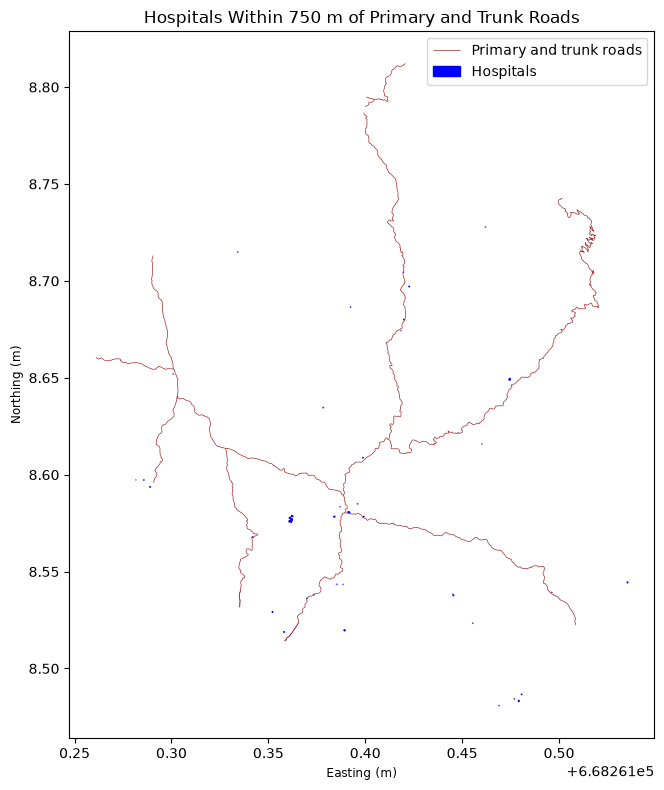

In [8]:
ax = primary_trunk_roads.plot(
    figsize=(10, 8),
    color="brown",
    linewidth=0.5,
    label="Primary and trunk roads"
)

near_hospitals.plot(
    ax=ax,
    color="blue",
    edgecolor="blue",
    markersize=100,
    label="Hospitals"
)

plt.title("Hospitals Within 750 m of Primary and Trunk Roads")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
"""6. Find the bridges that are on top of rivers. Print the total number of bridges and 
names of the bridge. """
bridges = roads[roads["bridge"] == "T"].copy()
rivers = waterways[waterways["fclass"].str.lower() == "river"].copy()

bridges = bridges.to_crs(epsg=32643)
rivers = rivers.to_crs(epsg=32643)

bridges_on_rivers = gpd.sjoin(
    bridges, rivers[["geometry"]],
    how="inner", predicate="intersects"
)

bridges_on_rivers = bridges_on_rivers[
    ~bridges_on_rivers.index.duplicated()
]

print("Total number of bridges on rivers:", len(bridges_on_rivers))
print("\nNames of bridges:")
print(bridges_on_rivers["name"].dropna().unique())

Total number of bridges on rivers: 52

Names of bridges:
<StringArray>
[                                            'MC Road',
                   'Thiruvanathapuram - Thenmala Road',
                               'Irumbupala Old Bridge',
                        'Nedumangad - Shorlacode Road',
                   'Thiruvananthapuram - Ponmudi Road',
                   'Netta Bridge (Old Rajapatha Road)',
                                  'LIC - Netta Bridge',
                                      'Mulamukku Road',
                          'Nedumangad Vattappara Road',
                                        'Uliyoor Road',
                          'Attingal - Nedumangad Road',
                                       'Enikkara road',
 'Check Dam cum Bridge at Kovil kadavu Aruvikkara(DS)',
                'Aruvikkara Check Dam cum Bridge (DS)',
                              'Irumbupalam New Bridge',
                                    'koovakudi bridge',
                                '

In [10]:
"""7. Find the primary and tertiary roads that are inside the forest. Print the names of 
the roads that are inside the forest."""
import geopandas as gpd
from pathlib import Path

if "data_dir" not in globals():
    data_dir = None
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidates = [
            base / "MTech26" / "lab 6" / "nedumangad_extracted" / "nedumangad",
            base / "Lab6" / "MTech26" / "lab 6" / "nedumangad_extracted" / "nedumangad",
        ]
        data_dir = next((path for path in candidates if path.exists()), None)
        if data_dir is not None:
            break

    if data_dir is None:
        raise FileNotFoundError("Could not locate the Nedumangad extracted data directory.")

if "roads" not in globals():
    roads = gpd.read_file(data_dir / "roads" / "nedumangad_road.shp")
if "lulc" not in globals():
    lulc = gpd.read_file(data_dir / "landuse" / "nedumangad_landuse.shp")

# The coordinate values are longitude/latitude. The shapefiles' .prj metadata
# reports projected CRSs, so override it before projecting consistently.
roads = roads.set_crs(epsg=4326, allow_override=True)
lulc = lulc.set_crs(epsg=4326, allow_override=True)

road_classes = roads["fclass"].astype(str).str.lower().str.strip()
selected_roads = roads[
    road_classes.isin(["primary", "tertiary"])
].copy()

forest = lulc[
    lulc["fclass"].astype(str).str.lower().str.strip().eq("forest")
].copy()


selected_roads = selected_roads.to_crs(epsg=32643)
forest = forest.to_crs(epsg=32643)

roads_in_forest = gpd.sjoin(
    selected_roads,
    forest[["geometry"]],
    how="inner",
    predicate="intersects"
)

roads_in_forest = roads_in_forest[
    ~roads_in_forest.index.duplicated()
]

print("Roads inside forest areas:")
print(roads_in_forest["name"].dropna().unique())

print("\nTotal road features found:", len(roads_in_forest))


Roads inside forest areas:
<StringArray>
['MEENMOOD KUTTIMOOD PUTHANKADA ROAD',  'Thiruvananthapuram - Ponmudi Road',
            'Vithura - Bonacaud Road']
Length: 3, dtype: str

Total road features found: 7


In [11]:
unique_roads = roads_in_forest["name"].dropna().unique()
print("Number of unique road names:", len(unique_roads))
print(unique_roads)

Number of unique road names: 3
<StringArray>
['MEENMOOD KUTTIMOOD PUTHANKADA ROAD',  'Thiruvananthapuram - Ponmudi Road',
            'Vithura - Bonacaud Road']
Length: 3, dtype: str
